# Practical Lab — Local AI with Ollama
**Running and Developing Local AI Applications** · PHD Student 

**Prerequisites:** Python 3.10+, basic Python, basic understanding of APIs, 8–16 GB RAM (NVIDIA GPU optional).

**Technologies:** Ollama · Python · REST API · `requests` · (optional) Open WebUI · a local LLM (Qwen, Gemma, Llama…)

> Ollama exposes a local HTTP service on `localhost:11434`, so the same model can be used from the terminal, Python, or any other software.

### How to use this notebook
- Run cells top to bottom. Cells starting with `!` run shell commands.
- Change `MODEL` / `MODEL2` below if the model names differ on your installation.
- Fill in the **✍️ Your answer** cells — they feed your final report.

## Part 1 — Understanding Local AI

**Cloud AI**
```
Python App → Internet → Cloud API → LLM
```
**Local AI**
```
Python App → localhost:11434 → Ollama → Local LLM → GPU / CPU
```
Advantages to investigate: **privacy**, **offline operation**, **no per-token cost**.
Trade-off: local models may be **less capable or slower** than frontier cloud models, depending on hardware and model size.

## Part 2 — Installing Ollama
### Exercise 1 — Verify the environment

In [1]:
import sys, platform
print("Python  :", sys.version)
print("System  :", platform.system(), platform.release())
assert sys.version_info >= (3, 10), "Python 3.10+ required"

Python  : 3.15.0 (tags/v3.15.0:d220409, Oct  9 2026, 11:55:56) [MSC v.1951 64 bit (AMD64)]
System  : Windows 10


In [2]:
!pip --version

pip 26.2.1 from C:\Users\Cloud\AppData\Local\Programs\Python\Python315\Lib\site-packages\pip (python 3.15)



### Exercise 2 — Install Ollama
Download the installer for your OS from <https://ollama.com/download> (Linux: `curl -fsSL https://ollama.com/install.sh | sh`). Then verify:

In [3]:
!ollama --version

ollama version is 0.40.6


Make sure the Ollama service is running (the desktop app starts it automatically; otherwise run `ollama serve` in a separate terminal).

In [4]:
import requests

OLLAMA = "http://localhost:11434"

try:
    r = requests.get(OLLAMA, timeout=3)
    print("✅ Ollama server reachable:", r.text)
except requests.exceptions.ConnectionError:
    print("❌ Ollama is not running. Start it with `ollama serve` in a terminal.")

✅ Ollama server reachable: Ollama is running


## Part 3 — Your First Local LLM
### Exercise 3 — Download a model
If the exact name differs on your installation, pick a small instruct/chat model suited to your hardware.

In [8]:
# Models used throughout the lab — edit if needed
MODEL  = "qwen3:0.6b" # Model 1
MODEL2 = "qwen3:4b" # Model 2 (used in the comparison parts)

In [9]:
!ollama pull {MODEL}

pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest 
pulling 7f4030143c1c: 100% ▕██████████████████▏ 522 MB                         
pulling ae370d884f10: 100% ▕██████████████████▏ 1.7 KB                         
pulling d18a5cc71b84: 100% ▕██████████████████▏  11 KB                         
pulling cff3f395ef37: 100% ▕██████████████████▏  120 B                         
pulling b0830f4ff6a0: 100% ▕██████████████████▏  490 B                         
verifying sha256 digest 
writing manifest 
removing unused layers 
success 


In [10]:
!ollama list

NAME                ID              SIZE      MODIFIED       
qwen3:0.6b          7df6b6e09427    522 MB    3 seconds ago     
moondream:latest    55fc3abd3867    1.7 GB    30 minutes ago    
qwen3:4b            359d7dd4bcda    2.5 GB    5 hours ago       
gemma3:4b           68ceab7e468a    3.4 GB    15 hours ago      
gemma3:latest       68ceab7e468a    3.4 GB    15 hours ago      


### Exercise 4 — Run the model
In the terminal you would use `ollama run qwen3.5`. Here we do the same thing through the API with a helper function.

In [8]:
import time, json

def generate(prompt, model=None, system=None, fmt=None, images=None, options=None, think=None):
    """Call Ollama /api/generate (non-streaming) and return the full JSON dict
    plus the measured wall-clock time under the key 'wall_s'."""
    payload = {"model": model or MODEL, "prompt": prompt, "stream": False}
    if system:  payload["system"] = system
    if fmt:     payload["format"] = fmt          # "json" or a JSON schema
    if images:  payload["images"] = images       # list of base64 strings
    if options: payload["options"] = options
    if think is not None: payload["think"] = think  # False disables 'thinking' on reasoning models
    t0 = time.perf_counter()
    r = requests.post(f"{OLLAMA}/api/generate", json=payload, timeout=600)
    r.raise_for_status()
    out = r.json()
    out["wall_s"] = time.perf_counter() - t0
    return out

def ask(prompt, **kw):
    """Shortcut: return only the text, and print timing."""
    out = generate(prompt, **kw)
    print(f"[{out['wall_s']:.1f}s]")
    return out["response"]

In [9]:
for p in [
    "Explain what artificial intelligence is in five sentences.",
    "Explain artificial intelligence to a 10-year-old child.",
    "Explain artificial intelligence to a computer science professor.",
]:
    print("="*80, "\nPROMPT:", p, "\n")
    print(ask(p))

PROMPT: Explain what artificial intelligence is in five sentences. 

[11.5s]
Artificial intelligence (AI) refers to the ability of machines to perform tasks that typically require human intelligence, such as learning, problem-solving, and decision-making, without being explicitly programmed. It relies on algorithms and data processing to make decisions, analyze patterns, and adapt to new information. AI systems process vast amounts of data, learn from experience, and improve over time, making them powerful tools in various fields. AI has significant implications for industries, from healthcare to finance, by enabling automation and enhancing efficiency. Ultimately, AI represents a bridge between human creativity and advanced computational capabilities.
PROMPT: Explain artificial intelligence to a 10-year-old child. 

[14.0s]
Sure! Here's how AI works in a way that a 10-year-old might understand:

Imagine a **robot** that plays games. It can **learn** by playing, and over time, it gets 

In [11]:
ask("What is artificial intelligence? Answer in two sentences.")

[12.1s]


'Artificial intelligence refers to the ability of machines to perform tasks that typically require human intelligence, such as learning, problem-solving, and decision-making. It involves complex systems that analyze data, learn patterns, and make decisions based on that information.  \n\nIn essence, AI is the intersection of algorithms, data, and learning, enabling machines to execute tasks requiring human-like reasoning.'

### Questions
1. Did the model produce different answers? Why?
2. Is the model communicating with a cloud API?
3. Where is inference being performed?
4. What happens if the Internet connection is disabled?

> 💡 Try it: disable Wi-Fi / unplug Ethernet and re-run the cell above.

**✍️ Your answer:**

1.Did the model produce different answers? Why? 
Yes. The model produced different answers because each prompt targeted a different audience and specified different requirements. The first response was a general explanation in five sentences, the second used simple language and everyday examples for a 10-year-old child, and the third used more technical vocabulary and concepts for a computer science professor.

2. Is the model communicating with a cloud API?

No. The Python program communicates with the local Ollama API running at http://localhost:11434. It does not need to send the prompt to a cloud API for inference.

3. Where is inference being performed?

Inference is performed locally on my computer by Ollama, using the downloaded qwen3:4b model. In my tests, the model ran on the CPU, as indicated by ollama ps showing 100% CPU.

4. What happens if the Internet connection is disabled?
After disabling the Wi-Fi connection, the model still generated a response in 12.1 seconds. This indicates that inference was performed locally through Ollama and that the prompt was not dependent on a cloud service. Internet access is needed to download models, updates, or software, but it is not required for generation once Ollama and the model are already installed.(see cell above).

## Part 4 — Experiment with Prompts
### Exercise 5 — Prompt engineering

In [12]:
prompt_a = """You are a university professor.

Explain the concept of a Directed Acyclic Graph (DAG).

Your answer must contain:
1. Definition
2. Example
3. Adjacency matrix
4. Real-world application
5. One Python example"""

print(ask(prompt_a))

[38.7s]
**Definition:**  
A Directed Acyclic Graph (DAG) is a graph in which there are no cycles, meaning there are no paths that loop indefinitely. It ensures that all nodes can be reached from any other without forming a loop.

---

**Example:**  
Imagine a project management problem with dependencies. Let’s say:  
- Node 0: Start project A  
- Node 1: Start project B  
- Node 2: Start project C  
- Node 3: End project C  

Edges represent dependencies:  
- A → B (A must come before B)  
- B → C (B must come before C)  

The adjacency matrix would look like:  
```
0 1 0 0  
1 0 0 0  
0 0 0 0  
0 0 0 0
```

---

**Real-World Application:**  
DAGs are used in project scheduling, dependency modeling, and algorithm design to ensure that dependencies are respected. They help in optimizing resource allocation and avoiding conflicts.

---

**Python Example:**  
Here’s a simple example:  
```python
# Define nodes as integers
nodes = [0, 1, 2, 3]

# Create adjacency matrix
adjacency_matrix = 

In [13]:
prompt_b = """You are a university professor.

Explain DAGs to a first-year computer science student.

Use simple language and one concrete example."""

print(ask(prompt_b))

[20.4s]
Sure! Here's how a DAG can be explained to a first-year student using a simple example:

**Example:**  
Imagine a **project timeline**. Each task is a **node**, and there's an **edge** from Task A to Task B if Task A must be completed **before** Task B.  

**Key points:**  
1. **No cycles**: If Task A → Task B → Task C, there’s a cycle (A → B → C), which is **not allowed** in a DAG.  
2. **Directed**: Only one direction of the edge.  
3. **Applications**: DAGs are used in project management (like scheduling) or algorithms (like finding the shortest path in a graph).  

**Why DAGs are important**:  
They help visualize dependencies and avoid infinite loops, which is crucial in real-world systems like workflows or algorithms. Let me know if you want more examples! 😊


### Questions
Compare the two answers. Explain the role of: **role · context · constraints · output format · specificity**.

**✍️ Your answer:**

The first answer is formal, detailed, and structured. It includes a definition, an example, an adjacency matrix, a real-world application, and Python code. The second answer uses simpler vocabulary and a concrete cake-baking example for a first-year student.

Role: “University professor” guides the model toward an educational and explanatory tone. Context: The target audience changes the language level: technical for the first answer and beginner-friendly for the second. Constraints: The first prompt requires five specific elements, while the second requires simple language and one concrete example. Output format: The required elements in the first prompt lead to a structured answer with sections, a table, and code; the second uses a simpler explanatory format. Specificity: More precise instructions produce a more targeted answer. However, the model did not fully respect conciseness in the second answer, showing that prompts guide output but do not guarantee perfect compliance.

## Part 5 — Model Management
### Exercise 6 — List, show, and monitor models

In [14]:
!ollama list

NAME             ID              SIZE      MODIFIED      
qwen3:0.6b       7df6b6e09427    522 MB    4 minutes ago    
qwen3:4b         359d7dd4bcda    2.5 GB    2 hours ago      
gemma3:4b        68ceab7e468a    3.4 GB    10 hours ago     
gemma3:latest    68ceab7e468a    3.4 GB    10 hours ago     


In [15]:
!ollama show {MODEL}

  Model
    architecture        qwen3      
    parameters          751.63M    
    context length      40960      
    embedding length    1024       
    quantization        Q4_K_M     

  Capabilities
    completion     
    tools          
    thinking       
        levels     false, true    
        default    true           

  Parameters
    stop              "<|im_start|>"    
    stop              "<|im_end|>"      
    temperature       0.6               
    top_k             20                
    top_p             0.95              
    repeat_penalty    1                 

  License
    Apache License               
    Version 2.0, January 2004    
    ...                          



In [16]:
!ollama ps

NAME          ID              SIZE      PROCESSOR    CONTEXT    RUNNER      UNTIL              
qwen3:0.6b    7df6b6e09427    1.0 GB    100% CPU     4096       llamacpp    4 minutes from now    


The same information is available from the REST API (`/api/tags`, `/api/show`, `/api/ps`):

In [17]:
import pandas as pd

def downloaded_models():
    tags = requests.get(f"{OLLAMA}/api/tags").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "family": m["details"].get("family"),
        "params": m["details"].get("parameter_size"),
        "quantization": m["details"].get("quantization_level"),
    } for m in tags])

def loaded_models():
    ps = requests.get(f"{OLLAMA}/api/ps").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "in_VRAM_GB": round(m.get("size_vram", 0)/1e9, 2),
        "expires_at": m.get("expires_at"),
    } for m in ps])

print("Downloaded:"); display(downloaded_models())
print("Currently loaded in memory:"); display(loaded_models())

Downloaded:


,name,size_GB,family,params,quantization
0,qwen3:0.6b,0.52,qwen3,751.63M,Q4_K_M
1,qwen3:4b,2.50,qwen3,4.0B,Q4_K_M
2,gemma3:4b,3.35,gemma3,3.9B,Q4_K_M
3,gemma3:latest,3.35,gemma3,3.9B,Q4_K_M


Currently loaded in memory:


,name,size_GB,in_VRAM_GB,expires_at
0,qwen3:0.6b,1.02,0.0,2026-10-21T11:53:08.3776861+01:00


### Questions
- What information do you get from `ollama list` vs `ollama ps`?
- What is the difference between a model that is **downloaded** and one that is **loaded**?

**✍️ Your answer:**

ollama list shows models stored on disk, while ollama ps shows models currently loaded in memory. A downloaded model is installed but inactive; a loaded model is active in RAM or VRAM and can generate responses.

## Part 6 — Compare Two Local Models
Install a second model suited to your computer.

In [18]:
!ollama pull {MODEL2}
!ollama list

pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest 
pulling 3e4cb1417446: 100% ▕██████████████████▏ 2.5 GB                         
pulling 2d54db2b9bb2: 100% ▕██████████████████▏ 1.5 KB                         
pulling d18a5cc71b84: 100% ▕██████████████████▏  11 KB                         
pulling cff3f395ef37: 100% ▕██████████████████▏  120 B                         
pulling e18a783aae55: 100% ▕██████████████████▏  487 B                         
verifying sha256 digest 
writing manifest 
removing unused layers ⠋ pulling manifest 
pulling 3e4cb1417446: 100% ▕██████████████████▏ 2.5 GB                         
pulling 2d54db2b9bb2: 100% ▕██████████████████▏ 1.5 KB                         
pulling d18a5cc71b84: 100% ▕██████████████████▏  11 KB                         
pulling cff3f395ef37: 100% ▕██████████████████▏  120 B                         
pulling e18a783aae55: 100% ▕██████████████████▏  487 B        

NAME             ID              SIZE      MODIFIED               
qwen3:4b         359d7dd4bcda    2.5 GB    Less than a second ago    
qwen3:0.6b       7df6b6e09427    522 MB    4 minutes ago             
gemma3:4b        68ceab7e468a    3.4 GB    10 hours ago              
gemma3:latest    68ceab7e468a    3.4 GB    10 hours ago              


### Exercise 7 — Same prompt, different models

In [19]:
prime_prompt = """Write a Python function that determines whether a number is prime.

Requirements:
- Python
- Type hints
- Docstring
- Explain the algorithm
- Give its time complexity"""

results = {}
for m in (MODEL, MODEL2):
    print("="*80, f"\nMODEL: {m}\n")
    out = generate(prime_prompt, model=m)
    results[m] = out
    print(out["response"])
    print(f"\n⏱ {out['wall_s']:.1f}s")

MODEL: qwen3:0.6b

Here's a Python function that determines whether a number is prime, with all required specifications:

```python
def is_prime(n):
    """
    Determines if a number is prime.

    Parameters:
    n (int): The number to check.

    Returns:
    bool: True if n is a prime number, False otherwise.

    Time Complexity:
    O(sqrt(n))
    """
    if n < 2:
        return False
    if n == 2:
        return True
    if n % 2 == 0:
        return False
    for i in range(3, int(n**0.5) + 1, 2):
        if n % i == 0:
            return False
    return True
```

### Explanation:
1. **Edge Case Handling**:
   - If `n < 2`, it's not a prime, so return `False`.
   - If `n == 2`, return `True` since 2 is the only even prime.

2. **Divisibility Check**:
   - If `n` is even and greater than 2, return `False` immediately since all even numbers greater than 2 are not prime.

3. **Loop Through Potential Divisors**:
   - Check divisibility starting from 3 up to the square root of `n

Now fill in your evaluation (scores out of 5) and see the table:

In [33]:
scores = {
    MODEL:  {"Response quality /5": 4, "Code correctness /5": 5},
    MODEL2: {"Response quality /5": 5, "Code correctness /5": 5},
}  # <- replace None with your scores

table = pd.DataFrame([
    {"Model": m, "Response time (s)": round(results[m]["wall_s"], 1), **scores[m]}
    for m in (MODEL, MODEL2)
])
table

,Model,Response time (s),Response quality /5,Code correctness /5
0,qwen3:0.6b,74.4,4,5
1,qwen3:4b,506.3,5,5


In [ ]:
#legend :
# 5/5: The code runs successfully and all tests pass.

# 4/5: The code works, but it is missing a minor detail.

# 3/5: The code works only for certain cases.

# 2/5: The code contains significant errors.

# 1/5: The code does not run or does not meet the requirements.

**Tip — test the generated code:** copy the function the model wrote into a cell and check it.

In [32]:
# Function generated by qwen3:0.6b
def is_prime(n):
    if n < 2:
        return False
    if n == 2:
        return True
    if n % 2 == 0:
        return False
    for i in range(3, int(n**0.5) + 1, 2):
        if n % i == 0:
            return False
    return True


# Test cases: input -> expected result
test_cases = {
    -7: False,
    0: False,
    1: False,
    2: True,
    3: True,
    4: False,
    9: False,
    11: True,
    15: False,
    17: True,
    25: False,
    97: True,
    100: False,
}

passed = 0

for number, expected in test_cases.items():
    actual = is_prime(number)
    status = "PASS" if actual == expected else "FAIL"

    print(
        f"is_prime({number}) -> "
        f"expected: {expected}, actual: {actual} [{status}]"
    )

    if actual == expected:
        passed += 1

failed = len(test_cases) - passed

print("\nTest summary")
print(f"Passed: {passed}/{len(test_cases)}")
print(f"Failed: {failed}/{len(test_cases)}")

if failed == 0:
    print("Code correctness: 5/5")
else:
    print("Code correctness: less than 5/5")

is_prime(-7) -> expected: False, actual: False [PASS]
is_prime(0) -> expected: False, actual: False [PASS]
is_prime(1) -> expected: False, actual: False [PASS]
is_prime(2) -> expected: True, actual: True [PASS]
is_prime(3) -> expected: True, actual: True [PASS]
is_prime(4) -> expected: False, actual: False [PASS]
is_prime(9) -> expected: False, actual: False [PASS]
is_prime(11) -> expected: True, actual: True [PASS]
is_prime(15) -> expected: False, actual: False [PASS]
is_prime(17) -> expected: True, actual: True [PASS]
is_prime(25) -> expected: False, actual: False [PASS]
is_prime(97) -> expected: True, actual: True [PASS]
is_prime(100) -> expected: False, actual: False [PASS]

Test summary
Passed: 13/13
Failed: 0/13
Code correctness: 5/5


In [34]:
# Function generated by qwen3:4b
def is_prime(n: int) -> bool:
    if n < 2:
        return False
    if n == 2:
        return True
    if n % 2 == 0:
        return False

    i = 3
    while i * i <= n:
        if n % i == 0:
            return False
        i += 2

    return True


# Test cases: input -> expected result
test_cases = {
    -7: False,
    0: False,
    1: False,
    2: True,
    3: True,
    4: False,
    9: False,
    11: True,
    15: False,
    17: True,
    25: False,
    97: True,
    100: False,
}

passed = 0

for number, expected in test_cases.items():
    actual = is_prime(number)
    status = "PASS" if actual == expected else "FAIL"

    print(
        f"is_prime({number}) -> "
        f"expected: {expected}, actual: {actual} [{status}]"
    )

    if actual == expected:
        passed += 1

failed = len(test_cases) - passed

print("\nTest summary")
print(f"Passed: {passed}/{len(test_cases)}")
print(f"Failed: {failed}/{len(test_cases)}")

if failed == 0:
    print("Code correctness: 5/5")
else:
    print("Code correctness: less than 5/5")

is_prime(-7) -> expected: False, actual: False [PASS]
is_prime(0) -> expected: False, actual: False [PASS]
is_prime(1) -> expected: False, actual: False [PASS]
is_prime(2) -> expected: True, actual: True [PASS]
is_prime(3) -> expected: True, actual: True [PASS]
is_prime(4) -> expected: False, actual: False [PASS]
is_prime(9) -> expected: False, actual: False [PASS]
is_prime(11) -> expected: True, actual: True [PASS]
is_prime(15) -> expected: False, actual: False [PASS]
is_prime(17) -> expected: True, actual: True [PASS]
is_prime(25) -> expected: False, actual: False [PASS]
is_prime(97) -> expected: True, actual: True [PASS]
is_prime(100) -> expected: False, actual: False [PASS]

Test summary
Passed: 13/13
Failed: 0/13
Code correctness: 5/5


In [35]:
def is_prime_reference(n: int) -> bool:
    if n < 2: return False
    if n < 4: return True
    if n % 2 == 0: return False
    i = 3
    while i * i <= n:
        if n % i == 0: return False
        i += 2
    return True

# Paste the model's function below as `candidate` and compare:
# candidate = is_prime
# assert all(candidate(n) == is_prime_reference(n) for n in range(-5, 2000)), "Incorrect!"
# print("✅ candidate matches the reference on 0..2000")

In [36]:
# Function generated by qwen3:0.6b
def is_prime(n):
    """
    Determines whether n is a prime number.
    """
    if n < 2:
        return False
    if n == 2:
        return True
    if n % 2 == 0:
        return False

    for i in range(3, int(n**0.5) + 1, 2):
        if n % i == 0:
            return False

    return True


# Reference implementation
def is_prime_reference(n: int) -> bool:
    if n < 2:
        return False
    if n < 4:
        return True
    if n % 2 == 0:
        return False

    i = 3
    while i * i <= n:
        if n % i == 0:
            return False
        i += 2

    return True


# Compare the model's function with the reference function
candidate = is_prime

assert all(
    candidate(n) == is_prime_reference(n)
    for n in range(-5, 2000)
), "Incorrect!"

print("✅ Candidate matches the reference for all values from -5 to 1999")

✅ Candidate matches the reference for all values from -5 to 1999


In [38]:
# Function generated by qwen3:4b
def is_prime(n: int) -> bool:
    """
    Check whether n is a prime number.
    """
    if n < 2:
        return False
    if n == 2:
        return True
    if n % 2 == 0:
        return False

    i = 3
    while i * i <= n:
        if n % i == 0:
            return False
        i += 2

    return True


# Reference implementation
def is_prime_reference(n: int) -> bool:
    if n < 2:
        return False
    if n < 4:
        return True
    if n % 2 == 0:
        return False

    i = 3
    while i * i <= n:
        if n % i == 0:
            return False
        i += 2

    return True


# Compare the second model's function with the reference
candidate = is_prime

assert all(
    candidate(n) == is_prime_reference(n)
    for n in range(-5, 2000)
), "Incorrect!"

print("✅ Candidate matches the reference for all values from -5 to 1999")

✅ Candidate matches the reference for all values from -5 to 1999


### Questions
Which model is faster? Which produces better code? Which uses more memory? Which would you choose for programming assistance? Is the largest model necessarily the best?

**✍️ Your answer:**

The qwen3:0.6b model is faster. Its response time was 74.4 seconds, compared with 506.3 seconds for qwen3:4b.

Both models produced correct code: both passed all reference tests from -5 to 1999 and received 5/5 for code correctness. However, qwen3:4b produced a more detailed and better-explained answer, so it received the higher response-quality score.

The qwen3:4b model uses more memory because it has more parameters. The qwen3:0.6b model is smaller and requires fewer resources.

For quick programming assistance and limited hardware, I would choose qwen3:0.6b because it is much faster and still produced correct code. For more complex programming tasks, I would choose qwen3:4b because its explanations are more complete.

The largest model is not necessarily the best. The best model depends on the task, the required quality, the response time, and the available memory. In this experiment, qwen3:4b provided better explanations, but qwen3:0.6b offered much faster responses with the same code-correctness score.

## Part 7 — Using Local AI from Python
### Exercise 8 — Python + Ollama
Project structure:
```
local_ai_lab/
├── app.py
├── requirements.txt
└── README.md
```
Install `requests` (already available here):

In [39]:
!pip install -q requests


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [46]:
import os
os.makedirs("local_ai_lab", exist_ok=True)

In [47]:
%%writefile local_ai_lab/app.py
import requests

url = "http://localhost:11434/api/generate"

data = {
    "model": "qwen3:0.6b",
    "prompt": "Explain recursion in Python.",
    "stream": False
}

response = requests.post(url, json=data)
result = response.json()
print(result["response"])

Overwriting local_ai_lab/app.py


In [48]:
%%writefile local_ai_lab/requirements.txt
requests

Overwriting local_ai_lab/requirements.txt


In [49]:
%%writefile local_ai_lab/README.md
# local_ai_lab
Minimal Python client for a local Ollama server.
Run: `python app.py`

Overwriting local_ai_lab/README.md


In [50]:
!python local_ai_lab/app.py

Recursion in Python is a programming technique where a function calls itself to solve a smaller subproblem. It breaks down a complex task into smaller, similar subproblems until a base case is reached, which is the point where the recursion stops.

### Example:
```python
def factorial(n):
    if n == 0 or n == 1:
        return 1
    return n * factorial(n - 1)

# Example usage
print(factorial(5))  # Output: 120
```

### Key Points:
1. **Base Case**: When `n == 0` or `n == 1`, the function returns 1, which handles the base case and stops the recursion.
2. **Recursive Step**: The function calls itself with `n - 1` to solve a smaller subproblem.
3. **Efficiency**: While recursion is not the most efficient for large inputs, it's a good way to handle smaller problems.

### Explanation in Python:
- The function defines a base case where `n == 0` or `n == 1` returns 1.
- For `n > 1`, it recursively calls itself with `n - 1`, multiplying the result by `n`.

This approach allows the problem to

**Architecture:** `Python → HTTP POST → localhost:11434 → Ollama → Local LLM → response → Python`

Below is the same call shown step by step, including the **metadata** Ollama returns:

In [51]:
out = generate("Explain recursion in Python.")
print(out["response"][:600], "...\n")
print({k: v for k, v in out.items() if k not in ("response", "context", "thinking")})

Recursion is a programming technique where a function calls itself to solve a smaller instance of the same problem. Here's a structured explanation in Python:

### Key Concepts:
1. **Base Case**: A condition that stops the recursion. For example, if `n == 0`, the function returns 0.
2. **Recursive Call**: The function calls itself with a smaller value, solving a subproblem.

### Example in Python:
```python
def sum_numbers(n):
    if n == 0:
        return 0
    else:
        return n + sum_numbers(n - 1)
```

### How It Works:
- When `n = 5`, the function calls itself with `n = 4`.
- This con ...

{'model': 'qwen3:0.6b', 'created_at': '2026-10-21T11:51:46.7810855Z', 'done': True, 'done_reason': 'stop', 'total_duration': 42531242600, 'load_duration': 22101800, 'prompt_eval_count': 16, 'prompt_eval_cached_count': 15, 'prompt_eval_duration': 31982000, 'eval_count': 1124, 'eval_duration': 42427556000, 'wall_s': 44.601287900004536}


## Part 8 — Build a Local AI Chatbot
### Exercise 9 — Interactive chatbot
`input()` works inside Jupyter (a prompt box appears). Type `exit` to stop.

In [52]:
URL = f"{OLLAMA}/api/generate"

def ask_ai(prompt):
    data = {"model": MODEL, "prompt": prompt, "stream": False}
    response = requests.post(URL, json=data)
    response.raise_for_status()
    return response.json()["response"]

def chat_loop_stateless():
    print("Local AI Assistant\nType 'exit' to stop.")
    while True:
        question = input("\nYou: ")
        if question.lower() == "exit":
            break
        print("\nAI:", ask_ai(question))

# chat_loop_stateless()   # <- uncomment to run

In [53]:
# Non-interactive test (works without typing):
for q in ["What is machine learning?", "Explain reinforcement learning."]:
    print("You:", q); print("AI:", ask_ai(q)[:500], "...\n")

You: What is machine learning?
AI: Machine learning is a subset of artificial intelligence that involves training algorithms to learn patterns from data and make decisions or predictions with minimal human intervention. The core idea is that machines can improve their performance by learning from data, rather than being explicitly programmed to do so. Here's a breakdown:

1. **Basic Concepts**:  
   - **Algorithms**: These are the rules or procedures the machine uses to process data.  
   - **Models**: These are specific algorith ...

You: Explain reinforcement learning.
AI: Reinforcement Learning (RL) is a type of machine learning where an agent (often a learner or autonomous agent) learns to make decisions by interacting with an environment. The goal is to maximize cumulative rewards through trial and error, with the environment providing feedback in the form of rewards or penalties. Here's a breakdown:

1. **Agent and Environment**:  
   The agent is an entity (e.g., a robot, player

In [54]:
exit

## Part 9 — Add Conversation Memory
The previous app treats each question independently. We now send the **conversation history** with each request.

In [7]:
import requests

MODEL = "qwen3:0.6b"
URL = "http://localhost:11434/api/generate"

history = []

def ask_ai_memory(question):
    history.append(f"User: {question}")
    prompt = "\n".join(history) + "\nAssistant:"

    data = {
        "model": MODEL,
        "prompt": prompt,
        "stream": False
    }

    response = requests.post(URL, json=data)
    response.raise_for_status()

    answer = response.json()["response"]
    history.append(f"Assistant: {answer}")

    return answer

In [9]:
history = []

def ask_ai_memory(question):
    history.append(f"User: {question}")
    prompt = "\n".join(history) + "\nAssistant:"
    data = {"model": MODEL, "prompt": prompt, "stream": False}
    response = requests.post(URL, json=data)
    response.raise_for_status()
    answer = response.json()["response"]
    history.append(f"Assistant: {answer}")
    return answer

def chat_loop_memory():
    while True:
        question = input("\nYou: ")
        if question.lower() == "exit":
            break
        print("\nAI:", ask_ai_memory(question))

# chat_loop_memory()   # <- uncomment for interactive use

In [10]:
history.clear()
for q in ["My name is Ahmed.", "What is my name?"]:
    print("You:", q)
    print("AI :", ask_ai_memory(q), "\n")

You: My name is Ahmed.
AI : Ahmed, thank you for sharing your name! How can I help you today? 

You: What is my name?
AI : Ahmed, thank you for sharing your name! How can I help you today? 



In [11]:
print("What the model actually received on the last call:\n" + "-"*50)
print("\n".join(history[:-1]) + "\nAssistant:")

What the model actually received on the last call:
--------------------------------------------------
User: My name is Ahmed.
Assistant: Ahmed, thank you for sharing your name! How can I help you today?
User: What is my name?
Assistant:


### Question
Why does the model remember the name? Is the LLM itself remembering?

**✍️ Your answer:**

*(Hint: look at the printed prompt above. Is anything stored inside the model between calls?)*
The model remembers the name because the Python application stores the conversation history in the `history` variable and sends it again with each new request. The printed prompt shows the previous message, “User: My name is Ahmed,” before the question “What is my name?”

The LLM itself is not permanently remembering the name between calls. Nothing is stored inside the model after the request ends. The apparent memory is managed by the application, which includes the previous conversation in the next prompt.

---
#### Better approach: the `/api/chat` endpoint
Ollama also has a chat endpoint taking structured `messages` (with `system` / `user` / `assistant` roles) and applying the model's own chat template.

In [13]:
import requests
OLLAMA = "http://localhost:11434"

In [14]:
def chat(messages, model=None, **kw):
    payload = {"model": model or MODEL, "messages": messages, "stream": False, **kw}
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    r.raise_for_status()
    return r.json()

msgs = [{"role": "system", "content": "You are a concise assistant."},
        {"role": "user", "content": "My name is Ahmed."}]
reply = chat(msgs)["message"]
msgs.append(reply)
msgs.append({"role": "user", "content": "What is my name?"})
print(chat(msgs)["message"]["content"])

Hello, Ahmed! I'm here to help. What can I assist you with? 😊


## Part 10 — Local AI for Software Engineering
### Exercise 10 — Code assistant

In [16]:
import time
import requests

OLLAMA = "http://localhost:11434"
MODEL = "qwen3:0.6b"

def generate(prompt, model=None, system=None, fmt=None, images=None, options=None, think=None):
    payload = {
        "model": model or MODEL,
        "prompt": prompt,
        "stream": False
    }
    if system:
        payload["system"] = system
    if fmt:
        payload["format"] = fmt
    if images:
        payload["images"] = images
    if options:
        payload["options"] = options
    if think is not None:
        payload["think"] = think

    t0 = time.perf_counter()
    r = requests.post(f"{OLLAMA}/api/generate", json=payload, timeout=600)
    r.raise_for_status()
    out = r.json()
    out["wall_s"] = time.perf_counter() - t0
    return out

def ask(prompt, **kw):
    out = generate(prompt, **kw)
    print(f"{out['wall_s']:.1f}s")
    return out["response"]

In [17]:
java_review = """You are a senior Java developer.

Review the following Java code:

public class Calculator {

    public int divide(int a, int b) {
        return a / b;
    }
}

Identify:
1. Potential problems
2. Runtime errors
3. Improvements
4. Corrected code"""

print(ask(java_review))

52.2s
1. **Potential Problems**  
   - **Division by Zero Error**: The method currently returns a float, which could cause unexpected behavior if division by zero is attempted.  
   - **Data Type Limitation**: The method returns a result as an integer, which may not handle cases where a is not divisible by b.  

2. **Runtime Errors**  
   - **Division by Zero**: If the method is called with `b == 0`, it throws an exception, which is a runtime error.  

3. **Improvements**  
   - Add checks to handle division by zero and ensure valid integer division.  
   - Consider using integer division instead of float to avoid floating-point issues.  

4. **Corrected Code**  
   ```java
   public class Calculator {

       public int divide(int a, int b) {
           if (b == 0) {
               throw new IllegalArgumentException("Division by zero is not allowed.");
           }
           return a / b;
       }
   }
   ```  

   **Explanation**:  
   - The corrected code adds exception handling fo

In [18]:
buggy = """You are a senior Java developer.

Find the bug in this code and explain how to fix it:

public class Student {

    private String name;
    private int age;

    public Student(String name) {
        this.name = name;
    }

    public void setAge(int age) {
        age = age;
    }

    public String getName() {
        return name;
    }
}"""

print(ask(buggy))

156.2s
The code as written has a **bug** in its constructor and setter methods. Here's the breakdown:

### **Bug in the Code**
1. **Constructor Parameter Issue**:  
   The constructor accepts a `String` for `name`, but it should instead initialize the `age` variable. If the `age` is supposed to be an `int`, the constructor should not require it to be a String. This is a **missing initialization** of the `age` field.

2. **Setter Method Problem**:  
   The `setAge` method is declared as `public void setAge(int age)`, which sets the `age` variable to an integer value. However, the constructor only initializes the `name` field. If the `age` is not properly initialized, the `age` field might be set to a value that is not valid for the intended use case (e.g., it could be an integer, but the constructor does not initialize it). This could lead to incorrect behavior, such as the `age` field being set to a string instead of an integer.

### **Fixing the Code**
To fix these issues, we need to:

> ✅ Expected finding: `age = age;` assigns the parameter to itself (variable shadowing); it should be `this.age = age;`. Did your model find it? Is `age` also never initialized in the constructor?

In [ ]:
The model found the expected bug: Yes.
Was age initialized explicitly in the constructor? No.
Was the bug corrected? Yes.

## Part 11 — Structured Output
### Exercise 11
First, the naive approach: ask for "ONLY JSON" in the prompt.

In [19]:
json_prompt = """Analyze the following student:

Name: Ahmed
Age: 21
Grade: 15.5
Absences: 2

Return ONLY JSON with this structure:

{
  "name": "...",
  "age": 0,
  "grade": 0,
  "risk": "...",
  "recommendation": "..."
}"""

raw = ask(json_prompt, think=False)
print(raw)

5.4s
```json
{
  "name": "Ahmed",
  "age": 0,
  "grade": 0,
  "risk": "low",
  "recommendation": "Check with a teacher or parent for guidance"
}
```


In [25]:
import json

In [26]:
import re

def extract_json(text):
    """Robust parsing: strip ```json fences and grab the first {...} block."""
    text = re.sub(r"```(?:json)?", "", text).strip()
    m = re.search(r"\{.*\}", text, re.DOTALL)
    return json.loads(m.group(0))

try:
    print(extract_json(raw))
except Exception as e:
    print("❌ Could not parse:", e)

{'name': 'Ahmed', 'age': 0, 'grade': 0, 'risk': 'low', 'recommendation': 'Check with a teacher or parent for guidance'}


Better: use Ollama's **structured outputs** — pass a JSON Schema in `format` so the output is constrained to be valid.

In [27]:
schema = {
    "type": "object",
    "properties": {
        "name": {"type": "string"},
        "age": {"type": "integer"},
        "grade": {"type": "number"},
        "risk": {"type": "string", "enum": ["low", "medium", "high"]},
        "recommendation": {"type": "string"},
    },
    "required": ["name", "age", "grade", "risk", "recommendation"],
}

out = generate(json_prompt, fmt=schema, think=False)
student = json.loads(out["response"])
print(json.dumps(student, indent=2))
print("Type of grade:", type(student["grade"]))

{
  "name": "Ahmed",
  "age": 0,
  "grade": 0,
  "risk": "low",
  "recommendation": "enroll in a summer school program to improve academic performance and build social connections with peers."
}
Type of grade: <class 'int'>


### Question
Why is structured output important when integrating an LLM into a software application?

**✍️ Your answer:**

Structured output is important because it makes an LLM’s response predictable and easier for a software application to process. By using a defined schema, the application receives the required fields and valid data types instead of unpredictable text. This reduces parsing errors, improves reliability, and makes it easier to validate, store, or display the result. It also helps prevent invalid values, such as an incorrect risk category, from entering the application.


## Part 12 — Local AI Document Assistant
Create `documents/course.txt`:

In [38]:
import os

os.makedirs("documents", exist_ok=True)

with open("documents/course.txt", "w", encoding="utf-8") as f:
    f.write(
        "Machine learning is a branch of artificial intelligence. "
        "Supervised learning uses labelled data. "
        "Unsupervised learning works with unlabelled data. "
        "Reinforcement learning learns through interaction with an environment "
        "using rewards and penalties."
    )

print("Created:", os.path.exists("documents/course.txt"))

Created: True


In [40]:
with open("documents/course.txt", "r", encoding="utf-8") as file:
    document = file.read()

print(document)

Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.



In [26]:
os.makedirs("documents", exist_ok=True)
with open("documents/course.txt", "w", encoding="utf-8") as f:
    f.write("""Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.
""")

### Exercise 12 — Read the document and ask questions

In [42]:
with open("documents/course.txt", "r", encoding="utf-8") as file:
    document = file.read()
print(document)

Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.



In [43]:
def ask_document(question, document):
    prompt = f"""
Answer the question using only the following document.

DOCUMENT:
{document}

QUESTION:
{question}

If the answer is not contained in the document,
say: "Information not available."
"""
    return ask(prompt, think=False)

print(ask_document("What is reinforcement learning?", document))
print()
print(ask_document("What is quantum computing?", document))

4.3s
Information not available.

2.4s
Information not available.


**Observe:** the second answer should be *"Information not available."* — the model is grounded in the supplied document instead of its own training data. Does your model respect the instruction every time?

**✍️ Your observation:**

The model followed the instruction for the second question because quantum computing was not mentioned in the document. However, it did not answer the first question correctly, even though the document contained the relevant information about reinforcement learning. This shows that document grounding is useful but not perfectly reliable every time.

## Part 13 — Mini-RAG
We create four documents, then build a **local retriever** that picks the most relevant one for a question and feeds it to the LLM.

In [28]:
docs = {
"ai.txt": """Artificial intelligence (AI) is the field of computer science that builds systems able to perform tasks normally requiring human intelligence, such as reasoning, perception, language understanding and decision making. AI includes machine learning, expert systems, robotics and natural language processing.""",

"machine_learning.txt": """Machine learning is a branch of artificial intelligence. Supervised learning uses labelled data to learn a mapping from inputs to outputs (classification, regression). Unsupervised learning works with unlabelled data to discover structure such as clusters. Overfitting happens when a model memorises training data and generalises poorly.""",

"reinforcement_learning.txt": """Reinforcement learning learns through interaction with an environment using rewards and penalties. An agent observes a state, chooses an action, and receives a reward. The goal is to learn a policy that maximises the cumulative reward. Q-learning and policy gradients are common algorithms.""",

"deep_learning.txt": """Deep learning uses artificial neural networks with many layers to learn representations from large amounts of data. Convolutional neural networks are used for images, recurrent networks and transformers for sequences and language. Training deep networks usually requires GPUs.""",
}

for name, text in docs.items():
    with open(f"documents/{name}", "w", encoding="utf-8") as f:
        f.write(text)
os.listdir("documents")

['.biblio_gemini_model.txt',
 '.biblio_graph_settings.txt',
 'ai.txt',
 'Article 1.pdf',
 'Capture d’écran 2026-02-19 170218.jpg',
 'Capture d’écran 2026-05-06 102028.jpg',
 'Classeur1.xlsx',
 'course.txt',
 'Custom Office Templates',
 'deep_learning.txt',
 'desktop.ini',
 'Freemake',
 'M02 Transport et logistique TRA-TSET.pdf',
 'machine_learning.txt',
 'Modèles Office personnalisés',
 'Mr Andriy Slyusarenko.pdf',
 'My Data Sources',
 'My Music',
 'My Pictures',
 'My Videos',
 'Offshore Safety Training Quality Survey.pdf',
 'ordre de mission.pdf',
 'reinforcement_learning.txt',
 'temp',
 'Zoom']

In [45]:
%%writefile rag.py
"""Mini-RAG: a tiny local retriever + prompt builder (keyword TF-IDF, no extra libraries)."""
import math, os, re
from collections import Counter

STOPWORDS = set("""a an the of to in on and or is are was were be by for with as at from that this
it its what which who how why when where do does did can could should would about into using use
learn learns through between such""".split())


def tokenize(text):
    return [w for w in re.findall(r"[a-zA-Z]+", text.lower()) if w not in STOPWORDS]


def load_documents(folder="documents"):
    docs = {}
    for fn in sorted(os.listdir(folder)):
        if fn.endswith(".txt"):
            with open(os.path.join(folder, fn), encoding="utf-8") as f:
                docs[fn] = f.read()
    return docs


class Retriever:
    def __init__(self, docs):
        self.docs = docs
        self.tokens = {n: Counter(tokenize(t)) for n, t in docs.items()}
        df = Counter(w for c in self.tokens.values() for w in c)
        N = len(docs)
        self.idf = {w: math.log((N + 1) / (d + 0.5)) for w, d in df.items()}

    def score(self, question):
        q = tokenize(question)
        return {
            name: sum(self.idf.get(w, 0) * (1 + math.log(c[w])) for w in set(q) if c[w] > 0)
            for name, c in self.tokens.items()
        }

    def top(self, question, k=1, min_score=0.01):
        ranked = sorted(self.score(question).items(), key=lambda x: -x[1])
        return [(n, s) for n, s in ranked[:k] if s >= min_score]

    def context(self, question, k=1):
        hits = self.top(question, k)
        return hits, "\n\n".join(f"[{n}]\n{self.docs[n]}" for n, _ in hits)


def build_prompt(question, context):
    return f"""Answer the question using only the CONTEXT below.
If the answer is not contained in the context, say: "Information not available."

CONTEXT:
{context if context else '(no relevant document found)'}

QUESTION:
{question}
"""

Writing rag.py


In [49]:
import importlib, rag
importlib.reload(rag)

retriever = rag.Retriever(rag.load_documents("documents"))

def rag_answer(question, k=1, model=None):
    hits, ctx = retriever.context(question, k)
    out = generate(rag.build_prompt(question, ctx), model=model, think=False)
    return hits, out["response"], out["wall_s"]

for q in ["What is reinforcement learning?",
          "Which hardware is needed to train neural networks with many layers?",
          "What is supervised learning?",
          "Who won the 2018 World Cup?"]:
    hits, ans, t = rag_answer(q)
    print(f"Q: {q}\n  retrieved: {hits}\n  A: {ans.strip()}\n  ({t:.1f}s)\n")

Q: What is reinforcement learning?
  retrieved: [('course.txt', 2.05727967535628)]
  A: Reinforcement learning learns through interaction with an environment using rewards and penalties.
  (2.5s)

Q: Which hardware is needed to train neural networks with many layers?
  retrieved: [('deep_learning.txt', 10.176841870048676)]
  A: GPU.
  (2.2s)

Q: What is supervised learning?
  retrieved: [('course.txt', 2.05727967535628)]
  A: Supervised learning uses labelled data.
  (2.4s)

Q: Who won the 2018 World Cup?
  retrieved: []
  A: Information not available.
  (2.2s)



**Architecture**
```
Documents → Local Retriever → Relevant Context → Ollama → Local LLM → Answer
```
This is the fundamental idea behind **Retrieval-Augmented Generation (RAG)**.

#### Optional extension — semantic retrieval with embeddings
Keyword matching fails when the question uses different words than the document. Ollama can also compute embeddings locally (`ollama pull nomic-embed-text`).

In [50]:
EMBED_MODEL = "nomic-embed-text"
# !ollama pull {EMBED_MODEL}      # <- uncomment once

import numpy as np

def embed(texts):
    r = requests.post(f"{OLLAMA}/api/embed", json={"model": EMBED_MODEL, "input": texts})
    r.raise_for_status()
    return np.array(r.json()["embeddings"])

def semantic_top(question, docs, k=1):
    names = list(docs)
    D = embed([docs[n] for n in names]); q = embed([question])[0]
    sims = D @ q / (np.linalg.norm(D, axis=1) * np.linalg.norm(q))
    return sorted(zip(names, sims), key=lambda x: -x[1])[:k]

# print(semantic_top("What hardware accelerates network training?", rag.load_documents("documents"), k=2))

## Part 14 — Local AI Vision *(optional)*
Requires a **multimodal** model, e.g. `ollama pull gemma3` (vision-capable variants), `llava`, `qwen2.5vl`, `llama3.2-vision`.

In [1]:
VISION_MODEL = "moondream"   # change to a vision-capable model you have installed
IMAGE_PATH = "Image.jpg"  # put an image next to the notebook

In [2]:
import os

print(os.path.exists(IMAGE_PATH))

True


In [4]:
import time, json, requests

OLLAMA = "http://localhost:11434"
MODEL = "qwen3:4b"

def generate(prompt, model=None, system=None, fmt=None, images=None, options=None, think=None):
    payload = {"model": model or MODEL, "prompt": prompt, "stream": False}
    if system:
        payload["system"] = system
    if fmt:
        payload["format"] = fmt
    if images:
        payload["images"] = images
    if options:
        payload["options"] = options
    if think is not None:
        payload["think"] = think

    t0 = time.perf_counter()
    r = requests.post(f"{OLLAMA}/api/generate", json=payload, timeout=600)
    r.raise_for_status()
    out = r.json()
    out["wall_s"] = time.perf_counter() - t0
    return out

def ask(prompt, **kw):
    out = generate(prompt, **kw)
    print(f"{out['wall_s']:.1f}s")
    return out["response"]


1. Airplane 
⏱ 26.8s


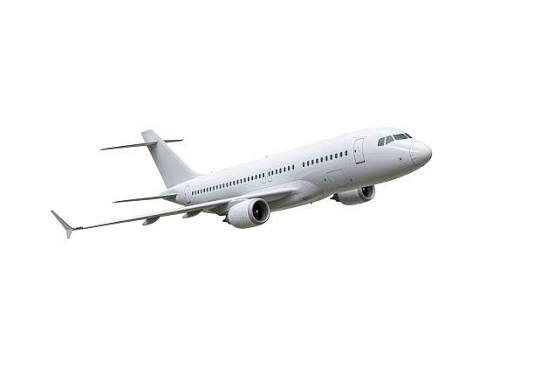

In [5]:
import base64

def analyze_image(path, model):
    with open(path, "rb") as f:
        b64 = base64.b64encode(f.read()).decode()
    prompt = """Analyze this image.

Identify:
1. Main objects
2. Environment
3. Text visible in the image
4. Possible interpretation"""
    return generate(prompt, model=model, images=[b64])

if os.path.exists(IMAGE_PATH):
    out = analyze_image(IMAGE_PATH, VISION_MODEL)
    print(out["response"], f"\n⏱ {out['wall_s']:.1f}s")
    from IPython.display import Image, display
    display(Image(IMAGE_PATH, width=400))
else:
    print(f"⚠️ Put an image named '{IMAGE_PATH}' next to this notebook, then re-run.")

### Questions
- Difference between an LLM and a multimodal model?
- What additional information does the vision model receive?
- Which applications could use local vision AI? *(document analysis, OCR, industrial inspection, education, medical-image preprocessing, surveillance analysis…)*

**✍️ Your answer:**
- Difference between an LLM and a multimodal model?
An LLM mainly processes and generates text. A multimodal model can process different types of data, such as text and images, and combine them to produce an answer.
- What additional information does the vision model receive?
The vision model receives the image itself in addition to the text prompt. It can analyze visual information such as objects, shapes, colors, surroundings, and visible text.
Which applications could use local vision AI? 
Local vision AI can be used for document analysis, OCR, industrial inspection, education, medical-image preprocessing, and surveillance analysis. Running it locally can help keep sensitive images on the computer instead of sending them to a cloud service.

## Part 15 — Build a Local AI Web Application
Structure:
```
local-ai-web/
├── app.py
├── templates/index.html
└── static/
```

In [6]:
!pip install -q flask requests
os.makedirs("local-ai-web/templates", exist_ok=True)
os.makedirs("local-ai-web/static", exist_ok=True)


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
%%writefile local-ai-web/app.py
from flask import Flask, render_template, request
import requests

app = Flask(__name__)

OLLAMA_URL = "http://localhost:11434/api/generate"
MODEL = "qwen3.5"


@app.route("/", methods=["GET", "POST"])
def index():
    answer = ""

    if request.method == "POST":
        question = request.form["question"]
        data = {"model": MODEL, "prompt": question, "stream": False}
        response = requests.post(OLLAMA_URL, json=data)
        answer = response.json()["response"]

    return render_template("index.html", answer=answer)


if __name__ == "__main__":
    app.run(debug=True)

Writing local-ai-web/app.py


In [8]:
%%writefile local-ai-web/templates/index.html
<!DOCTYPE html>
<html>
<head>
    <title>Local AI Assistant</title>
</head>
<body>

<h1>Local AI Assistant</h1>

<form method="POST">
    <textarea name="question" rows="8" cols="70" placeholder="Ask your local AI..."></textarea>
    <br><br>
    <button type="submit">Ask</button>
</form>

{% if answer %}
<h2>Response</h2>
<pre>{{ answer }}</pre>
{% endif %}

</body>
</html>

Writing local-ai-web/templates/index.html


Run it **from a terminal** (not inside the notebook):
```bash
cd local-ai-web
python app.py
```
then open <http://127.0.0.1:5000>. 🎉 You now have a complete local AI web application.

*(📸 Take a screenshot for your report: `screenshots/06_webapp.png`.)*

## Part 16 — Performance Benchmark
We measure: response time, model size, tokens generated, tokens/second, RAM and GPU consumption.

Ollama returns precise counters: `eval_count` (generated tokens), `eval_duration` (ns), `prompt_eval_count`, `load_duration`.

In [12]:
!pip install -q psutil


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
import importlib
import pandas as pd

In [15]:
%%writefile benchmark.py
"""Benchmark local Ollama models on the same prompt."""
import time, requests, psutil, pandas as pd

OLLAMA = "http://localhost:11434"
PROMPT = "Write a 500-word explanation of reinforcement learning."


def unload(model):
    requests.post(f"{OLLAMA}/api/generate", json={"model": model, "keep_alive": 0})
    time.sleep(2)


def loaded_info(model):
    for m in requests.get(f"{OLLAMA}/api/ps").json()["models"]:
        if m["name"].startswith(model.split(":")[0]):
            return m["size"] / 1e9, m.get("size_vram", 0) / 1e9
    return float("nan"), float("nan")


def bench(model, prompt=PROMPT, runs=1):
    rows = []
    for _ in range(runs):
        unload(model)                       # cold start, so the load time is visible
        t0 = time.perf_counter()
        r = requests.post(f"{OLLAMA}/api/generate",
                          json={"model": model, "prompt": prompt, "stream": False,
                                "think": False}, timeout=900).json()
        wall = time.perf_counter() - t0
        total_gb, vram_gb = loaded_info(model)
        rows.append({
            "Model": model,
            "Disk size (GB)": next((m["size"] / 1e9 for m in requests.get(f"{OLLAMA}/api/tags").json()["models"]
                                    if m["name"].startswith(model.split(":")[0])), float("nan")),
            "Loaded size (GB)": total_gb,
            "VRAM (GB)": vram_gb,
            "Load time (s)": r.get("load_duration", 0) / 1e9,
            "Response time (s)": wall,
            "Tokens": r.get("eval_count"),
            "Tokens/s": r["eval_count"] / (r["eval_duration"] / 1e9),
            "System RAM used (%)": psutil.virtual_memory().percent,
        })
    return pd.DataFrame(rows)


if __name__ == "__main__":
    import sys
    print(pd.concat([bench(m) for m in sys.argv[1:]]).round(2).to_string(index=False))

Writing benchmark.py


In [16]:
import benchmark; importlib.reload(benchmark)

bench_df = pd.concat([benchmark.bench(m) for m in (MODEL, MODEL2)], ignore_index=True)
bench_df["Quality /5"] = None   # <- fill in after reading both answers
bench_df.round(2)

,Model,Disk size (GB),Loaded size (GB),VRAM (GB),Load time (s),Response time (s),Tokens,Tokens/s,System RAM used (%),Quality /5
0,qwen3:0.6b,0.52,1.02,0.0,2.37,23.35,531,28.37,67.7,None
1,qwen3:4b,0.52,3.19,0.0,7.40,204.89,1193,6.14,83.5,None


In [42]:
import benchmark; importlib.reload(benchmark)

bench_df = pd.concat([benchmark.bench(m) for m in (MODEL, MODEL2)], ignore_index=True)
bench_df["Quality /5"] = 5,4   # <- fill in after reading both answers
bench_df.round(2)

,Model,Disk size (GB),Loaded size (GB),VRAM (GB),Load time (s),Response time (s),Tokens,Tokens/s,System RAM used (%),Quality /5
0,qwen3:0.6b,0.52,1.02,0.0,4.50,26.47,410,20.87,75.6,5
1,qwen3:4b,0.52,3.19,0.0,9.54,287.98,1302,4.74,89.5,4


In [18]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


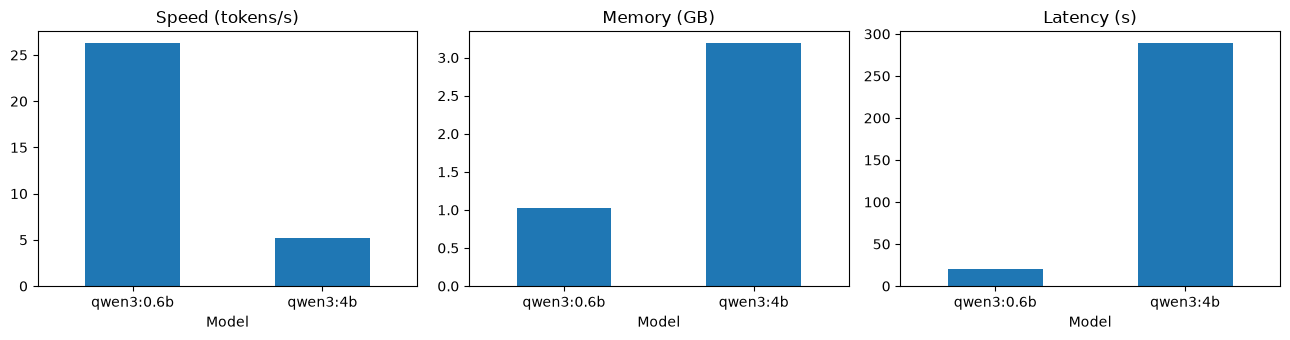

In [19]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
bench_df.plot.bar(x="Model", y="Tokens/s", ax=ax[0], legend=False, title="Speed (tokens/s)", rot=0)
bench_df.plot.bar(x="Model", y="Loaded size (GB)", ax=ax[1], legend=False, title="Memory (GB)", rot=0)
bench_df.plot.bar(x="Model", y="Response time (s)", ax=ax[2], legend=False, title="Latency (s)", rot=0)
plt.tight_layout(); plt.show()

### Discussion — the model-size trade-off
```
Model size ──► Quality
           ──► Memory
           ──► Latency
           ──► Hardware requirements
```
Local model selection should be based on **actual measurements on the target machine**, not just public benchmark rankings.

**✍️ Your discussion:**

Discussion — The Model-Size Trade-off

The benchmark shows a clear trade-off between model size, quality, memory usage, latency, and hardware requirements. qwen3:4b is larger and generated more tokens, but it required considerably more resources than qwen3:0.6b.

In terms of memory, qwen3:0.6b used 1.02 GB, whereas qwen3:4b used 3.19 GB. The larger model also increased system RAM usage from 67.7% to 83.5%, indicating higher hardware requirements.

The smaller model was significantly faster. It achieved 28.37 tokens/s, compared with only 6.14 tokens/s for qwen3:4b. Its total response time was also much lower: 23.35 seconds versus 204.89 seconds. The loading time followed the same pattern, with 2.37 seconds for qwen3:0.6b and 7.40 seconds for qwen3:4b.

The qwen3:4b model generated more tokens, 1,193 compared with 531, but generating a longer answer does not automatically mean that the answer is better. The quality scores were not recorded in this benchmark, so the quality advantage of the larger model cannot be confirmed using these measurements alone.

Based on the results on this computer, I would choose qwen3:0.6b for interactive applications because it is faster, uses less memory, and has lower hardware requirements. The qwen3:4b model could be selected when answer quality is more important than speed, provided that the computer has enough available RAM and the user accepts the much longer response time. Therefore, local model selection should be based on measurements from the target machine rather than only on public benchmark rankings.

## Part 17 — Final Mini Project: **FSTT Local AI Assistant**

**Functional requirements:** runs entirely locally · uses Ollama + a local LLM · web interface · answers questions about a supplied course · uses local documents as knowledge · maintains conversation history · structured responses for selected questions · displays the answer · records response time.

```
Browser → Flask/Python ─┬─ Conversation history ─┐
                        └─ Documents → Retriever ┴─► Ollama → Local LLM
```

We reuse `rag.py` and create the final deliverable layout:
```
LocalAI_Lab/
├── source/ (app.py, chatbot.py, rag.py, benchmark.py, templates/)
├── documents/
├── screenshots/
├── report.pdf
└── README.md
```

In [30]:
import shutil
base = "LocalAI_Lab"
for d in ("source/templates", "documents", "screenshots"):
    os.makedirs(f"{base}/{d}", exist_ok=True)

# copy shared modules and documents into the deliverable layout
shutil.copy("rag.py", f"{base}/source/rag.py")
shutil.copy("benchmark.py", f"{base}/source/benchmark.py")
for fn in os.listdir("documents"):
    src = f"documents/{fn}"
    if os.path.isfile(src):
        shutil.copy(src, f"{base}/documents/{fn}")
print(sorted(os.listdir(base)))

['documents', 'screenshots', 'source']


In [31]:
%%writefile LocalAI_Lab/source/chatbot.py
"""Console chatbot with conversation memory (uses /api/chat)."""
import requests

OLLAMA = "http://localhost:11434"
MODEL = "qwen3.5"


def main():
    messages = [{"role": "system", "content": "You are a helpful, concise assistant."}]
    print("Local AI Assistant — type 'exit' to stop.")
    while True:
        q = input("\nYou: ")
        if q.lower() == "exit":
            break
        messages.append({"role": "user", "content": q})
        r = requests.post(f"{OLLAMA}/api/chat",
                          json={"model": MODEL, "messages": messages, "stream": False})
        r.raise_for_status()
        reply = r.json()["message"]
        messages.append({"role": "assistant", "content": reply["content"]})
        print("\nAI:", reply["content"])


if __name__ == "__main__":
    main()

Writing LocalAI_Lab/source/chatbot.py


In [32]:
%%writefile LocalAI_Lab/source/app.py
"""FSTT Local AI Assistant — Flask + Ollama + local RAG + conversation history."""
import json, os, time
import requests
from flask import Flask, jsonify, render_template, request

import rag

OLLAMA = os.environ.get("OLLAMA_URL", "http://localhost:11434")
MODEL = os.environ.get("MODEL", "qwen3.5")
DOC_DIR = os.path.join(os.path.dirname(__file__), "..", "documents")
MAX_TURNS = 6                      # remembered user/assistant pairs

app = Flask(__name__)
retriever = rag.Retriever(rag.load_documents(DOC_DIR))
history = []                       # [{"role": ..., "content": ...}]  (single-user demo)

SYSTEM = ("You are the FSTT Local AI Assistant. Answer questions about the course using only the "
          "provided CONTEXT. If the answer is not in the context, say: \"Information not available.\" "
          "Be concise.")

# Structured response schema used for "Analyze ..." / "Quiz ..." style questions
STRUCT_SCHEMA = {
    "type": "object",
    "properties": {
        "topic": {"type": "string"},
        "summary": {"type": "string"},
        "key_points": {"type": "array", "items": {"type": "string"}},
        "difficulty": {"type": "string", "enum": ["easy", "medium", "hard"]},
    },
    "required": ["topic", "summary", "key_points", "difficulty"],
}


def call_ollama(messages, structured=False):
    payload = {"model": MODEL, "messages": messages, "stream": False, "think": False}
    if structured:
        payload["format"] = STRUCT_SCHEMA
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    r.raise_for_status()
    return r.json()


@app.route("/")
def index():
    return render_template("index.html", model=MODEL, docs=list(retriever.docs))


@app.route("/ask", methods=["POST"])
def ask():
    body = request.get_json(force=True)
    question = (body.get("question") or "").strip()
    structured = bool(body.get("structured"))
    if not question:
        return jsonify(error="Empty question"), 400

    hits, context = retriever.context(question, k=2)
    user_msg = f"CONTEXT:\n{context or '(none)'}\n\nQUESTION: {question}"
    messages = [{"role": "system", "content": SYSTEM}] + history[-2 * MAX_TURNS:] \
               + [{"role": "user", "content": user_msg}]

    t0 = time.perf_counter()
    try:
        out = call_ollama(messages, structured)
    except requests.RequestException as e:
        return jsonify(error=f"Ollama error: {e}"), 502
    elapsed = time.perf_counter() - t0

    answer = out["message"]["content"]
    # store the plain question (not the long context) to keep history small
    history.append({"role": "user", "content": question})
    history.append({"role": "assistant", "content": answer})

    parsed = None
    if structured:
        try:
            parsed = json.loads(answer)
        except json.JSONDecodeError:
            pass

    tokens = out.get("eval_count")
    tps = tokens / (out["eval_duration"] / 1e9) if tokens and out.get("eval_duration") else None
    return jsonify(answer=answer, structured=parsed,
                   sources=[{"doc": n, "score": round(s, 2)} for n, s in hits],
                   seconds=round(elapsed, 2), tokens=tokens,
                   tokens_per_s=round(tps, 1) if tps else None)


@app.route("/reset", methods=["POST"])
def reset():
    history.clear()
    return jsonify(ok=True)


if __name__ == "__main__":
    # Bind to localhost ONLY (see report question Q15 on security)
    app.run(host="127.0.0.1", port=int(os.environ.get("PORT", 5001)), debug=False)

Writing LocalAI_Lab/source/app.py


In [33]:
%%writefile LocalAI_Lab/source/templates/index.html
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<title>FSTT Local AI Assistant</title>
<style>
  body { font-family: system-ui, sans-serif; max-width: 820px; margin: 2rem auto; padding: 0 1rem; color:#222; }
  h1 { margin-bottom: .2rem; } .sub { color:#666; font-size:.9rem; margin-bottom:1rem; }
  #chat { border:1px solid #ddd; border-radius:8px; padding:1rem; height:420px; overflow-y:auto; background:#fafafa; }
  .msg { margin:.6rem 0; padding:.6rem .8rem; border-radius:8px; white-space:pre-wrap; }
  .user { background:#e3f0ff; } .ai { background:#fff; border:1px solid #e5e5e5; }
  .meta { font-size:.75rem; color:#777; margin-top:.3rem; }
  form { display:flex; gap:.5rem; margin-top:1rem; } input[type=text] { flex:1; padding:.6rem; }
  button { padding:.6rem 1rem; cursor:pointer; } label { font-size:.85rem; }
</style>
</head>
<body>
<h1>🎓 FSTT Local AI Assistant</h1>
<div class="sub">Model: <b>{{ model }}</b> · Documents: {{ docs|join(", ") }} · Runs 100% locally</div>
<div id="chat"></div>
<form id="f">
  <input type="text" id="q" placeholder="Ask a question about the course..." autocomplete="off" autofocus>
  <button type="submit">Ask</button>
  <button type="button" id="reset">Reset</button>
</form>
<label><input type="checkbox" id="struct"> Structured response (JSON)</label>

<script>
const chat = document.getElementById("chat");
function add(cls, text, meta) {
  const d = document.createElement("div"); d.className = "msg " + cls; d.textContent = text;
  if (meta) { const m = document.createElement("div"); m.className = "meta"; m.textContent = meta; d.appendChild(m); }
  chat.appendChild(d); chat.scrollTop = chat.scrollHeight; return d;
}
document.getElementById("f").onsubmit = async (e) => {
  e.preventDefault();
  const q = document.getElementById("q"); const question = q.value.trim(); if (!question) return;
  q.value = ""; add("user", question);
  const wait = add("ai", "…thinking…");
  try {
    const r = await fetch("/ask", {method:"POST", headers:{"Content-Type":"application/json"},
      body: JSON.stringify({question, structured: document.getElementById("struct").checked})});
    const j = await r.json(); wait.remove();
    if (j.error) { add("ai", "⚠️ " + j.error); return; }
    const text = j.structured ? JSON.stringify(j.structured, null, 2) : j.answer;
    const src = j.sources.map(s => s.doc).join(", ") || "none";
    add("ai", text, `⏱ ${j.seconds}s · ${j.tokens ?? "?"} tokens · ${j.tokens_per_s ?? "?"} tok/s · sources: ${src}`);
  } catch (err) { wait.remove(); add("ai", "⚠️ " + err); }
};
document.getElementById("reset").onclick = async () => { await fetch("/reset", {method:"POST"}); chat.innerHTML = ""; };
</script>
</body>
</html>

Writing LocalAI_Lab/source/templates/index.html


In [34]:
%%writefile LocalAI_Lab/README.md
# FSTT Local AI Assistant

A fully local assistant: Flask web UI → Ollama → local LLM, with a keyword (TF-IDF) retriever over `documents/`,
conversation history, structured (JSON) answers and response-time display.

## Setup
```bash
ollama pull qwen3.5
pip install flask requests psutil pandas
```

## Run
```bash
cd source
python app.py            # http://127.0.0.1:5001
python chatbot.py        # console chatbot
python benchmark.py qwen3.5 gemma3
```
Environment variables: `MODEL`, `OLLAMA_URL`, `PORT`.

Writing LocalAI_Lab/README.md


**Test the final app from the notebook:** launch it as a background process, send a few questions, then stop it.

In [39]:
import subprocess, sys, time

env = {**os.environ, "MODEL": MODEL, "PORT": "5001"}
server = subprocess.Popen([sys.executable, "app.py"], cwd="LocalAI_Lab/source", env=env,
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
time.sleep(3)

def app_ask(q, structured=False):
    r = requests.post("http://127.0.0.1:5001/ask", json={"question": q, "structured": structured}, timeout=600)
    return r.json()

try:
    for q, s in [("What is reinforcement learning?", False),
                 ("And how is it different from supervised learning?", False),   # tests history
                 ("Summarize deep learning", True),                              # structured
                 ("What is quantum computing?", False)]:                         # not in the docs
        j = app_ask(q, s)
        print(f"Q: {q}\nA: {j.get('structured') or j.get('answer') or j}\n"
              f"   sources={j.get('sources')} · {j.get('seconds')}s · {j.get('tokens_per_s')} tok/s\n")
finally:
    pass  # keep running so you can open http://127.0.0.1:5001 — stop in the next cell

Q: What is reinforcement learning?
A: Reinforcement learning learns through interaction with an environment using rewards and penalties.
   sources=[{'doc': 'course.txt', 'score': 2.06}, {'doc': 'reinforcement_learning.txt', 'score': 1.8}] · 2.62s · 33.9 tok/s

Q: And how is it different from supervised learning?
A: Reinforcement learning differs from supervised learning in that it learns through interaction with an environment using rewards and penalties, while supervised learning uses labelled data to learn a mapping from inputs to outputs.
   sources=[{'doc': 'course.txt', 'score': 2.06}, {'doc': 'machine_learning.txt', 'score': 1.95}] · 3.2s · 36.6 tok/s

Q: Summarize deep learning
A: {'difficulty': 'easy', 'key_points': ['Artificial neural networks with many layers', 'Learn representations from large amounts of data', 'Convolutional neural networks', 'Recurrent networks and transformers', 'Training with GPUs'], 'summary': 'Deep learning uses artificial neural networks with many la

In [38]:
server.terminate(); server.wait(timeout=10)
print("Server stopped.")

Server stopped.


> 📸 Open <http://127.0.0.1:5001> in your browser while the server is running and take your screenshots: `01_installation.png`, `02_model.png`, `03_chatbot.png`, `04_python.png`, `05_rag.png`, `06_webapp.png`.

## Part 18 — Questions for the Report
Answer each question in your own words (use your measurements from Parts 6 and 16 for Q13–Q14).

**Q1.** What is Local AI?

Local AI is artificial intelligence that runs directly on the user’s computer instead of sending prompts to a remote cloud service. In this project, Ollama runs the language model locally, so the questions and generated answers remain on the local machine

**Q2.** Difference between a Cloud LLM and a Local LLM?

A cloud LLM runs on remote servers and is accessed through the Internet or an online API. A local LLM runs on the user’s own computer. Cloud models usually provide more computing power and may be more capable, while local models provide better privacy, offline access, and no per-request cloud cost.

**Q3.** What role does Ollama play?

Ollama manages and runs language models locally. It downloads the models, loads them into memory, starts the local inference service, and provides an API that Python and Flask can use to send prompts and receive responses. Ollama’s local API is normally available at http://localhost:11434/api.

**Q4.** What is model quantization?

Model quantization is the process of representing model weights with fewer bits, such as 8-bit or 4-bit values instead of full-precision values. This reduces the model’s memory and storage requirements and can make local inference faster, although it may slightly reduce accuracy or output quality.

**Q5.** Why does model size affect memory consumption?

A larger model contains more parameters, and those parameters must be loaded into RAM or VRAM during inference. Therefore, larger models generally require more memory. In this benchmark, qwen3:4b used 3.19 GB when loaded, compared with 1.02 GB for qwen3:0.6b.

**Q6.** Why can a smaller model sometimes be preferable?

A smaller model can be preferable because it starts faster, responds faster, uses less memory, and works on less powerful hardware. It is also more suitable for interactive applications where low latency is important. In my test, qwen3:0.6b achieved 28.37 tokens/s, compared with 6.14 tokens/s for qwen3:4b.

**Q7.** Advantages of local inference?

The main advantages are:

- Better privacy because prompts and documents can remain on the computer.

- Operation without an Internet connection.

- No cloud API cost per token.

- Full control over the selected model and data.

- Easy integration with local Python applications.

**Q8.** Disadvantages of local inference?

The main disadvantages are:

- Local hardware limits the model size and speed.

- Larger models can require significant RAM or VRAM.

- Local models may be less capable than the best cloud models.

- The user is responsible for installing, updating, and securing the system.

- Inference can be slow on a CPU or on a computer with limited memory.

**Q9.** Explain the architecture of your Python application.

The application uses Flask as the web interface and Python as the application logic. The browser sends a question to the Flask server. The application keeps recent conversation history, searches the local course documents with the retriever, and builds a prompt containing the relevant context. It then sends this prompt to Ollama, receives the local LLM response, and returns the answer, retrieved sources, response time, and token statistics to the browser.

**Q10.** Explain the role of the REST API.

The REST API allows Python and Flask to communicate with Ollama through HTTP requests. For example, the application sends a POST request containing the model name, prompt, and options to Ollama’s /api/generate or /api/chat endpoint. Ollama then returns a JSON response containing the generated text and performance metadata. Local requests do not require an authentication header by default.

**Q11.** What is RAG?

RAG means Retrieval-Augmented Generation. Before generating an answer, the application searches external documents and adds the most relevant passages to the prompt. In this project, the retriever searches the local course files and Ollama generates an answer using the selected documents as context.

**Q12.** Difference between an LLM and a multimodal LLM?

A traditional LLM mainly processes and generates text. A multimodal LLM can work with several types of input, such as text and images, and sometimes audio or video. For example, a multimodal model could analyze an uploaded diagram, while a text-only LLM could only analyze a textual description of that diagram.

**Q13.** Compare two local models experimentally.

I compared qwen3:0.6b and qwen3:4b using the same prompt and the same computer. The smaller model was much faster and used less memory. The larger model generated more tokens, but it had a much longer response time. Because the quality score was not filled in during the benchmark, the measurements confirm the performance and resource differences, but they do not prove that qwen3:4b gives better answers.

| Metric           | qwen3:0.6b     | qwen3:4b      |
| ---------------- | -------------- | ------------- |
| Loaded size      | 1.02 GB        | 3.19 GB       |
| Load time        | 2.37 s         | 7.40 s        |
| Response time    | 23.35 s        | 204.89 s      |
| Tokens generated | 531            | 1,193         |
| Generation speed | 28.37 tokens/s | 6.14 tokens/s |
| System RAM used  | 67.7%          | 83.5%         |

**Q14.** Which model would you deploy on a computer with limited RAM? Explain.

I would deploy qwen3:0.6b on a computer with limited RAM. It used only 1.02 GB when loaded, compared with 3.19 GB for qwen3:4b, and it used less system RAM overall: 67.7% versus 83.5%. It was also much faster, reaching 28.37 tokens/s instead of 6.14 tokens/s. The larger model would only be preferable if its additional quality justified its higher memory usage and much longer response time.

**Q15.** What security risks exist when exposing a local LLM server to a network?

*(Hint: Ollama has no authentication by default; think about `OLLAMA_HOST=0.0.0.0`, unauthorized use of your compute, model/data exposure, prompt injection through documents, and what a reverse proxy with auth/TLS or a firewall would change.)*

The main risks are unauthorized use of the computer’s resources, exposure of private prompts or documents, model management by unauthorized users, and prompt injection through retrieved files. Ollama’s local API does not require authentication by default, so it should not be exposed directly to an untrusted network. The server should remain on localhost or be protected with firewall rules, authentication, and HTTPS/TLS through a reverse proxy.

## Part 19 — Deliverables
Final check of the submission folder:
```
LocalAI_Lab/
├── report.pdf
├── source/        app.py · chatbot.py · rag.py · benchmark.py
├── documents/     ai.txt · ml.txt · rl.txt  (+ the other course files)
├── screenshots/   01_installation.png … 06_webapp.png
└── README.md
```

In [43]:
required = [
    "LocalAI_Lab/report.pdf",
    "LocalAI_Lab/README.md",
    "LocalAI_Lab/source/app.py", "LocalAI_Lab/source/chatbot.py",
    "LocalAI_Lab/source/rag.py", "LocalAI_Lab/source/benchmark.py",
    "LocalAI_Lab/screenshots/01_installation.png", "LocalAI_Lab/screenshots/02_model.png",
    "LocalAI_Lab/screenshots/03_chatbot.png", "LocalAI_Lab/screenshots/04_python.png",
    "LocalAI_Lab/screenshots/05_rag.png", "LocalAI_Lab/screenshots/06_webapp.png",
]
for p in required:
    print("✅" if os.path.exists(p) else "⬜ missing", p)
print("\nDocuments:", sorted(os.listdir("LocalAI_Lab/documents")))

✅ LocalAI_Lab/report.pdf
✅ LocalAI_Lab/README.md
✅ LocalAI_Lab/source/app.py
✅ LocalAI_Lab/source/chatbot.py
✅ LocalAI_Lab/source/rag.py
✅ LocalAI_Lab/source/benchmark.py
✅ LocalAI_Lab/screenshots/01_installation.png
✅ LocalAI_Lab/screenshots/02_model.png
✅ LocalAI_Lab/screenshots/03_chatbot.png
✅ LocalAI_Lab/screenshots/04_python.png
✅ LocalAI_Lab/screenshots/05_rag.png
✅ LocalAI_Lab/screenshots/06_webapp.png

Documents: ['.biblio_gemini_model.txt', '.biblio_graph_settings.txt', '.ipynb_checkpoints', 'ai.txt', 'course.txt', 'deep_learning.txt', 'desktop.ini', 'machine_learning.txt', 'reinforcement_learning.txt']
